# PLL Optimal Jitter & Power vs Supply Voltage ($V_{\text{DD}}$)

This notebook analyzes the **supply voltage sensitivity** of optimal PLL loop filter configurations across core supply variations, as measured by [`sw/tests/pll_opt_jitter_vdd.py`](file:///users/micas/iramrezl/projects/lagd-meas/sw/tests/pll_opt_jitter_vdd.py).

---

### Measurement Scope & Objectives
1. **Core Supply Voltage Scaling ($V_{\text{DD}} \in [0.75, 0.70, 0.65, 0.60\,\text{V}]$)**:
   - Powers the PLL core via channel 2 of the Keysight E36312A power supply.
   - Evaluates closed-loop lock margin, loop bandwidth stability, and the minimum operating supply voltage ($V_{\text{DD,min}}$) for each target carrier frequency (4.8 GHz, 6.0 GHz, 7.0 GHz, and 8.0 GHz).
   - Early exit policy: if the PLL loses lock at a given $V_{\text{DD}}$, lower supply voltages are safely skipped for that configuration.
2. **Jitter Degradation vs Core Power Savings**:
   - Evaluates total RMS jitter $\sigma_t$, random noise jitter $\sigma_n$, periodic spur jitter $\sigma_s$, and analyzer Phase Noise Mode (PNM) jitter.
   - Core power dissipation scaling: $P_{\text{core}} = V_{\text{DD}} \cdot I_{\text{core}}$.
   - Figure of Merit: Power-Jitter trade-off ($P_{\text{core}} \times \sigma_t^2$).
3. **Phase Noise Spectra ($L(f)$)**:
   - Spectra referred to the VCO ($+20\log_{10} N$) showing in-band (charge pump headroom, loop bandwidth compression) vs out-of-band (VCO core tank amplitude) evolution.
4. **Reference Spur & Deterministic Tone Suppression**:
   - Variation of reference spur levels ($P_{\text{spur}}$ in dBc and dBm at $\pm f_{\text{ref}}$) vs $V_{\text{DD}}$.


In [61]:
%load_ext autoreload
%autoreload 2
%matplotlib inline


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### 1. Setup, Environment & Data Loader
Discovers the newest `pll_opt_jitter_vdd_<sample>_<timestamp>.csv` results file from `results/pll/`, or loads an explicit file specified by the user. If no run file exists yet, provides realistic mock data so all cells can be evaluated and previewed immediately.


In [62]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.colors import sample_colorscale

# Repository path setup (sw/tools/notebooks -> repo root)
REPO_ROOT = Path.cwd().resolve()
while REPO_ROOT.name != "lagd-meas" and REPO_ROOT.parent != REPO_ROOT:
    REPO_ROOT = REPO_ROOT.parent

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

PLL_DIR = REPO_ROOT / "results" / "pll"

# Visual styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 14,
    "lines.linewidth": 2.0,
    "lines.markersize": 7,
})

FREQ_COLORS = {
    4.8e9: "#2b5c8f",  # Blue
    6.0e9: "#2ca02c",  # Green
    7.0e9: "#e27c38",  # Orange
    8.0e9: "#9467bd",  # Purple
}

VDD_COLORS = {
    0.75: "#1f77b4",  # Nominal: Deep Blue
    0.70: "#2ca02c",  # 0.70 V: Green
    0.65: "#ff7f0e",  # 0.65 V: Orange
    0.60: "#d62728",  # 0.60 V: Red
}

GRID_COLOR = "#e4e3df"

def vdd_color(v):
    """Smooth viridis gradient mapping for supply voltages [0.60 .. 0.75 V]."""
    return sample_colorscale("Viridis", [min(max((v - 0.60) / 0.15, 0), 1) * 0.9])[0]

def bin_phase_noise(offsets, L_f, n_bins=300, f_start=1e3, f_stop=20e6):
    """Logarithmically bin phase noise curve for smooth plotting while preserving noise power."""
    f = np.asarray(offsets, dtype=float)
    l = np.asarray(L_f, dtype=float)
    mask = (f >= f_start) & (f <= f_stop)
    f, l = f[mask], l[mask]
    if len(f) < 2:
        return f, l
    edges = np.geomspace(f_start, f_stop, n_bins + 1)
    lin = 10.0 ** (l / 10.0)
    weight = np.gradient(f)
    bin_idx = np.digitize(f, edges) - 1
    out_f, out_l = [], []
    for i in range(len(edges) - 1):
        m = (bin_idx == i)
        if m.any() and weight[m].sum() > 0:
            out_f.append(np.sum(f[m] * weight[m]) / weight[m].sum())
            out_l.append(10.0 * np.log10(np.sum(lin[m] * weight[m]) / weight[m].sum()))
    return np.array(out_f), np.array(out_l)

def save_fig(fig, name, fig_dir=None, width=1100, height=550):
    """Save figure as HTML and optional PNG, inspired by pll_test_vdd.ipynb."""
    if fig_dir is not None:
        fig_dir = Path(fig_dir)
        fig_dir.mkdir(parents=True, exist_ok=True)
        fig.write_html(fig_dir / f"{name}.html")
        try:
            fig.write_image(fig_dir / f"{name}.png", width=width, height=height, scale=2)
        except Exception:
            pass
    fig.show()

def generate_mock_data():
    """Generates realistic mock data for previewing before running pll_opt_jitter_vdd.py."""
    rows = []
    trace_rows = []
    freqs = [4.8e9, 6.0e9, 7.0e9, 8.0e9]
    vdd_steps = [0.75, 0.70, 0.65, 0.60]
    
    # Realistic operational boundaries per frequency
    min_lock_map = {4.8e9: 0.65, 6.0e9: 0.65, 7.0e9: 0.70, 8.0e9: 0.70}
    base_jitter_map = {4.8e9: 1.35, 6.0e9: 1.55, 7.0e9: 1.85, 8.0e9: 2.15}
    base_current_map = {4.8e9: 24.5, 6.0e9: 26.0, 7.0e9: 27.5, 8.0e9: 29.0}
    
    offsets = np.geomspace(1e3, 20e6, 400)
    
    for f in freqs:
        f_ghz = f / 1e9
        min_v = min_lock_map[f]
        base_j = base_jitter_map[f]
        base_i = base_current_map[f]
        
        for v in vdd_steps:
            locked = 1 if v >= min_v else 0
            v_meas = v + np.random.normal(0, 0.001)
            i_ma = (base_i * (v / 0.75)**1.2) if locked else 4.0
            p_mw = v_meas * i_ma
            
            vdd_penalty = (0.75 - v) * 3.5
            total_j = (base_j + vdd_penalty + np.random.normal(0, 0.03)) if locked else np.nan
            noise_j = (total_j * 0.94) if locked else np.nan
            spur_j = (total_j * 0.34) if locked else np.nan
            pnm_j = (total_j * 0.98) if locked else np.nan
            carrier_dbm = (1.5 - (0.75 - v) * 4.0) if locked else -50.0
            ref_spur_dbc = (-68.0 + (0.75 - v) * 12.0) if locked else np.nan
            
            row = {
                "time": "2026-11-05T12:00:00",
                "f_vco": f,
                "f_ref": f / 64,
                "total_div": 64,
                "sample": "S5",
                "config_label": f"{f_ghz:.1f}GHz_opt",
                "vco_tune_coarse": 0,
                "vco_current_min": 0,
                "vco_current_max": 0,
                "set_current": 7,
                "set_r1": 7,
                "set_c1": 7,
                "set_c2": 0,
                "locked": locked,
                "pll_vdd": v_meas,
                "vdd_set": v,
                "pll_i": i_ma / 1e3,
                "pll_p": p_mw / 1e3,
                "carrier_dbm": carrier_dbm,
                "time_jitter_trace_ps": total_j,
                "time_jitter_noise_ps": noise_j,
                "time_jitter_spur_ps": spur_j,
                "time_jitter_pnm_ps": pnm_j,
                "ref_spur_dbc": ref_spur_dbc,
                "ref_spur_vco_dbc": (ref_spur_dbc + 20 * math.log10(64)) if not np.isnan(ref_spur_dbc) else np.nan,
                "status": "ok" if locked else "unlocked",
            }
            rows.append(row)
            
            if locked:
                div_db = 20 * math.log10(64)
                bw = (400e3 * (v / 0.75))
                inband = -92.0 + (0.75 - v) * 5.0 - div_db
                vco_1m = -118.0 + (0.75 - v) * 8.0 - div_db
                
                l_pad = 10 * np.log10(
                    10**(inband / 10) / (1 + (offsets / bw)**2) +
                    10**(vco_1m / 10) / (1 + (1e6 / offsets)**2) +
                    10**(-148.0 / 10)
                )
                for off, lvl in zip(offsets, l_pad):
                    trace_rows.append({
                        "f_vco": f,
                        "pll_vdd": v_meas,
                        "vdd_set": v,
                        "kind": "L_trace",
                        "freq": off,
                        "level_dbm": lvl,
                        "set_current": 7, "set_r1": 7, "set_c1": 7, "set_c2": 0
                    })
            else:
                break
                
    df_runs = pd.DataFrame(rows)
    df_traces = pd.DataFrame(trace_rows)
    return df_runs, df_traces, True

def load_pll_vdd_data(csv_path=None):
    """Loads PLL VDD sweep data from CSV, or auto-discovers latest run."""
    if csv_path is None:
        matches = sorted(
            [p for p in PLL_DIR.glob("pll_opt_jitter_vdd_*.csv") if not p.stem.endswith("_traces")],
            key=lambda p: p.stat().st_mtime
        )
        if matches:
            csv_path = matches[-1]
            
    if csv_path is not None and Path(csv_path).is_file():
        csv_file = Path(csv_path)
        print(f"Loading real measurement run: {csv_file.name}")
        df = pd.read_csv(csv_file)
        traces_file = csv_file.with_name(csv_file.stem + "_traces.csv")
        traces = pd.read_csv(traces_file) if traces_file.is_file() else pd.DataFrame()
        is_mock = False
    else:
        print("No pll_opt_jitter_vdd_*.csv found in results/pll/.")
        print("Generating realistic simulated data so the notebook can be fully explored.")
        print("Run `python sw/tests/pll_opt_jitter_vdd.py` to produce real lab measurements.\n")
        df, traces, is_mock = generate_mock_data()
        csv_file = Path("pll_opt_jitter_vdd_simulated.csv")
        
    if "pll_p_mw" not in df.columns and "pll_p" in df.columns:
        df["pll_p_mw"] = df["pll_p"] * 1e3
    if "pll_i_ma" not in df.columns and "pll_i" in df.columns:
        df["pll_i_ma"] = df["pll_i"] * 1e3
    if "f_ghz" not in df.columns and "f_vco" in df.columns:
        df["f_ghz"] = (df["f_vco"] / 1e9).round(1)
    if "p_eff_mw_per_ghz" not in df.columns and "pll_p_mw" in df.columns and "f_vco" in df.columns:
        df["p_eff_mw_per_ghz"] = df["pll_p_mw"] / (df["f_vco"] / 1e9)
    if "f_ghz" not in df.columns and "f_vco" in df.columns:
        df["f_ghz"] = (df["f_vco"] / 1e9).round(1)
        
    if "config_label" not in df.columns:
        if all(c in df.columns for c in ["set_current", "set_r1", "set_c1", "set_c2"]):
            df["config_label"] = df.apply(
                lambda r: f"I={int(r['set_current'])}, R1={int(r['set_r1'])}, C1={int(r['set_c1'])}, C2={int(r['set_c2'])}"
                if pd.notna(r.get("set_current")) else (f"{r['f_vco']/1e9:.1f}GHz_opt" if "f_vco" in r and pd.notna(r.get("f_vco")) else "opt_cfg"),
                axis=1
            )
        else:
            df["config_label"] = df.apply(
                lambda r: f"{r['f_vco']/1e9:.1f}GHz_opt" if "f_vco" in r and pd.notna(r.get("f_vco")) else "opt_cfg",
                axis=1
            )

    target_steps = np.array([0.75, 0.70, 0.65, 0.60])
    if "vdd_set" not in df.columns:
        df["vdd_set"] = df["pll_vdd"].apply(lambda v: target_steps[np.argmin(np.abs(target_steps - v))])
    if not traces.empty and "vdd_set" not in traces.columns and "pll_vdd" in traces.columns:
        traces["vdd_set"] = traces["pll_vdd"].apply(lambda v: target_steps[np.argmin(np.abs(target_steps - v))])

    return df, traces, csv_file, is_mock

# ==============================================================================
# RUN SELECTION
# Set RESULT_CSV = None for auto-detection, or specify a specific Path
# ==============================================================================
RESULT_CSV = None

df_runs, df_traces, active_csv, is_mock = load_pll_vdd_data(RESULT_CSV)
FIG_DIR = active_csv.with_name(active_csv.stem + "_figures")
print(f"Loaded {len(df_runs)} measurement points across {df_runs['f_ghz'].nunique()} operating frequencies.")


Loading real measurement run: pll_opt_jitter_vdd_S5_20261105_120653.csv
Loaded 8 measurement points across 2 operating frequencies.


### 2. Run Overview & Lock Margin Summary
Summary of all measured frequencies and supply voltages, evaluating lock status, jitter degradation, and core power reduction.


In [63]:
def get_primary_jitter(row_or_df):
    """Return PNM jitter as primary truth, falling back to trace jitter if PNM is missing."""
    if isinstance(row_or_df, pd.DataFrame):
        if "time_jitter_pnm_ps" in row_or_df.columns and row_or_df["time_jitter_pnm_ps"].notna().any():
            return row_or_df["time_jitter_pnm_ps"].fillna(row_or_df.get("time_jitter_trace_ps", np.nan))
        return row_or_df.get("time_jitter_trace_ps", pd.Series(index=row_or_df.index, dtype=float))
    # Series / dict-like
    if "time_jitter_pnm_ps" in row_or_df and pd.notna(row_or_df["time_jitter_pnm_ps"]):
        return row_or_df["time_jitter_pnm_ps"]
    return row_or_df.get("time_jitter_trace_ps", np.nan)

def format_vdd_summary_table(df):
    """Format complete measurement results across VDD steps with PNM jitter as primary truth."""
    d = df.copy()
    d["Lock Status"] = d["locked"].apply(lambda x: "LOCKED" if x == 1 else "LOST LOCK")
    d["Freq (GHz)"] = d["f_ghz"].apply(lambda f: f"{f:.1f}")
    d["VDD Target (V)"] = d["vdd_set"].apply(lambda v: f"{v:.2f}")
    d["VDD Meas (V)"] = d["pll_vdd"].apply(lambda v: f"{v:.3f}")
    d["Power (mW)"] = d["pll_p_mw"].apply(lambda p: f"{p:.2f}" if not pd.isna(p) else "n/a")
    d["Current (mA)"] = d["pll_i_ma"].apply(lambda i: f"{i:.2f}" if not pd.isna(i) else "n/a")
    
    # PNM Jitter (Primary Truth) & Trace Jitter
    if "time_jitter_pnm_ps" in d.columns:
        d["PNM Jitter (ps)"] = d["time_jitter_pnm_ps"].apply(lambda j: f"{j:.2f}" if not pd.isna(j) else "n/a")
    else:
        d["PNM Jitter (ps)"] = "n/a"
    d["Trace Jitter (ps)"] = d.get("time_jitter_trace_ps", pd.Series(index=d.index)).apply(lambda j: f"{j:.2f}" if not pd.isna(j) else "n/a")
    d["Noise Jitter (ps)"] = d.get("time_jitter_noise_ps", pd.Series(index=d.index)).apply(lambda j: f"{j:.2f}" if not pd.isna(j) else "n/a")
    d["Spur Jitter (ps)"] = d.get("time_jitter_spur_ps", pd.Series(index=d.index)).apply(lambda j: f"{j:.2f}" if not pd.isna(j) else "n/a")
    if "ref_spur_dbc" in d.columns:
        d["Ref Spur (dBc)"] = d["ref_spur_dbc"].apply(lambda s: f"{s:.1f}" if not pd.isna(s) else "n/a")
    if "p_eff_mw_per_ghz" in d.columns or ("pll_p_mw" in d.columns and "f_vco" in d.columns):
        if "p_eff_mw_per_ghz" not in d.columns:
            d["p_eff_mw_per_ghz"] = d["pll_p_mw"] / (d["f_vco"] / 1e9)
        d["Power Eff (mW/GHz)"] = d["p_eff_mw_per_ghz"].apply(lambda e: f"{e:.3f}" if not pd.isna(e) else "n/a")
        
    cols = ["Freq (GHz)", "VDD Target (V)", "VDD Meas (V)", "Lock Status",
            "PNM Jitter (ps)", "Trace Jitter (ps)", "Noise Jitter (ps)", "Spur Jitter (ps)"]
    if "Ref Spur (dBc)" in d.columns:
        cols.append("Ref Spur (dBc)")
    cols.extend(["Power (mW)", "Current (mA)", "Power Eff (mW/GHz)"])
    
    return d[cols].reset_index(drop=True)

def compute_lock_margins(df):
    """Computes VDD,min, jitter penalty, and power savings for each frequency."""
    summary = []
    for f, grp in df.groupby("f_ghz"):
        locked_grp = grp[grp["locked"] == 1].sort_values("vdd_set")
        
        nom_row = grp[grp["vdd_set"] == 0.75]
        if not nom_row.empty and nom_row.iloc[0]["locked"] == 1:
            nom_j = get_primary_jitter(nom_row.iloc[0])
            nom_p = nom_row.iloc[0]["pll_p_mw"]
        else:
            nom_j = np.nan
            nom_p = np.nan
            
        if not locked_grp.empty:
            min_v = locked_grp["vdd_set"].min()
            min_row = locked_grp[locked_grp["vdd_set"] == min_v].iloc[0]
            min_j = get_primary_jitter(min_row)
            min_p = min_row["pll_p_mw"]
            delta_j = min_j - nom_j
            delta_p_pct = (1.0 - min_p / nom_p) * 100.0 if nom_p > 0 else np.nan
        else:
            min_v = np.nan
            min_j = np.nan
            delta_j = np.nan
            delta_p_pct = np.nan
            
        summary.append({
            "Frequency": f"{f:.1f} GHz",
            "Nominal PNM Jitter @ 0.75V (ps)": f"{nom_j:.2f}" if not np.isnan(nom_j) else "n/a",
            "Nominal Power @ 0.75V (mW)": f"{nom_p:.2f}" if not np.isnan(nom_p) else "n/a",
            "Min Lock VDD (V)": f"{min_v:.2f}" if not np.isnan(min_v) else "Failed",
            "PNM Jitter @ VDD,min (ps)": f"{min_j:.2f}" if not np.isnan(min_j) else "n/a",
            "Jitter Penalty Δσ (ps)": f"+{delta_j:.2f}" if not np.isnan(delta_j) else "n/a",
            "Core Power Savings (%)": f"{delta_p_pct:.1f}%" if not np.isnan(delta_p_pct) else "n/a",
            "Nominal Eff @ 0.75V (mW/GHz)": f"{nom_p / f:.3f}" if not np.isnan(nom_p) else "n/a",
            "Eff @ VDD,min (mW/GHz)": f"{min_p / f:.3f}" if not np.isnan(min_p) else "n/a",
        })
    return pd.DataFrame(summary).set_index("Frequency")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("=" * 85)
print("  COMPLETE VDD SENSITIVITY MEASUREMENT TABLE")
print("=" * 85)
display(format_vdd_summary_table(df_runs))

print("\n" + "=" * 85)
print("  LOCK MARGIN & LOW-SUPPLY EFFICIENCY BENCHMARK")
print("=" * 85)
display(compute_lock_margins(df_runs))


  COMPLETE VDD SENSITIVITY MEASUREMENT TABLE


,Freq (GHz),VDD Target (V),VDD Meas (V),Lock Status,PNM Jitter (ps),Trace Jitter (ps),Noise Jitter (ps),Spur Jitter (ps),Ref Spur (dBc),Power (mW),Current (mA),Power Eff (mW/GHz)
0,4.8,0.75,0.750,LOCKED,15.99,16.71,16.69,0.75,-40.8,0.98,1.30,0.204
1,4.8,0.70,0.700,LOCKED,17.39,17.02,17.00,0.75,-41.4,0.88,1.25,0.182
2,4.8,0.65,0.652,LOCKED,18.53,18.50,18.49,0.75,-42.4,0.79,1.21,0.164
3,4.8,0.60,0.602,LOCKED,22.88,23.13,23.11,0.74,-44.1,0.70,1.16,0.146
4,8.0,0.75,0.750,LOCKED,18.11,17.11,17.11,0.13,-32.5,1.62,2.16,0.202
5,8.0,0.70,0.700,LOCKED,19.08,17.33,17.33,0.13,-32.8,1.46,2.08,0.182
6,8.0,0.65,0.652,LOCKED,18.97,17.81,17.81,0.12,-33.3,1.31,2.02,0.164
7,8.0,0.60,0.602,LOST LOCK,n/a,n/a,n/a,n/a,n/a,1.18,1.95,0.147



  LOCK MARGIN & LOW-SUPPLY EFFICIENCY BENCHMARK


,Nominal PNM Jitter @ 0.75V (ps),Nominal Power @ 0.75V (mW),Min Lock VDD (V),"PNM Jitter @ VDD,min (ps)",Jitter Penalty Δσ (ps),Core Power Savings (%),Nominal Eff @ 0.75V (mW/GHz),"Eff @ VDD,min (mW/GHz)"
Frequency,,,,,,,,
4.8 GHz,15.99,0.98,0.60,22.88,+6.89,28.4%,0.204,0.146
8.0 GHz,18.11,1.62,0.65,18.97,+0.86,18.8%,0.202,0.164


### 3. Jitter Scaling vs Supply Voltage ($V_{\text{DD}}$)
Visualizes jitter scaling as $V_{\text{DD}}$ drops from nominal ($0.75\,\text{V}$) down to $0.60\,\text{V}$.
Following instrument validation, the **FSW K40 Phase Noise Mode (PNM) jitter** is taken as the **primary source of truth**, cross-compared against the stitched spectrum integration (`time_jitter_trace_ps`), random noise (`time_jitter_noise_ps`), and periodic spurs (`time_jitter_spur_ps`).


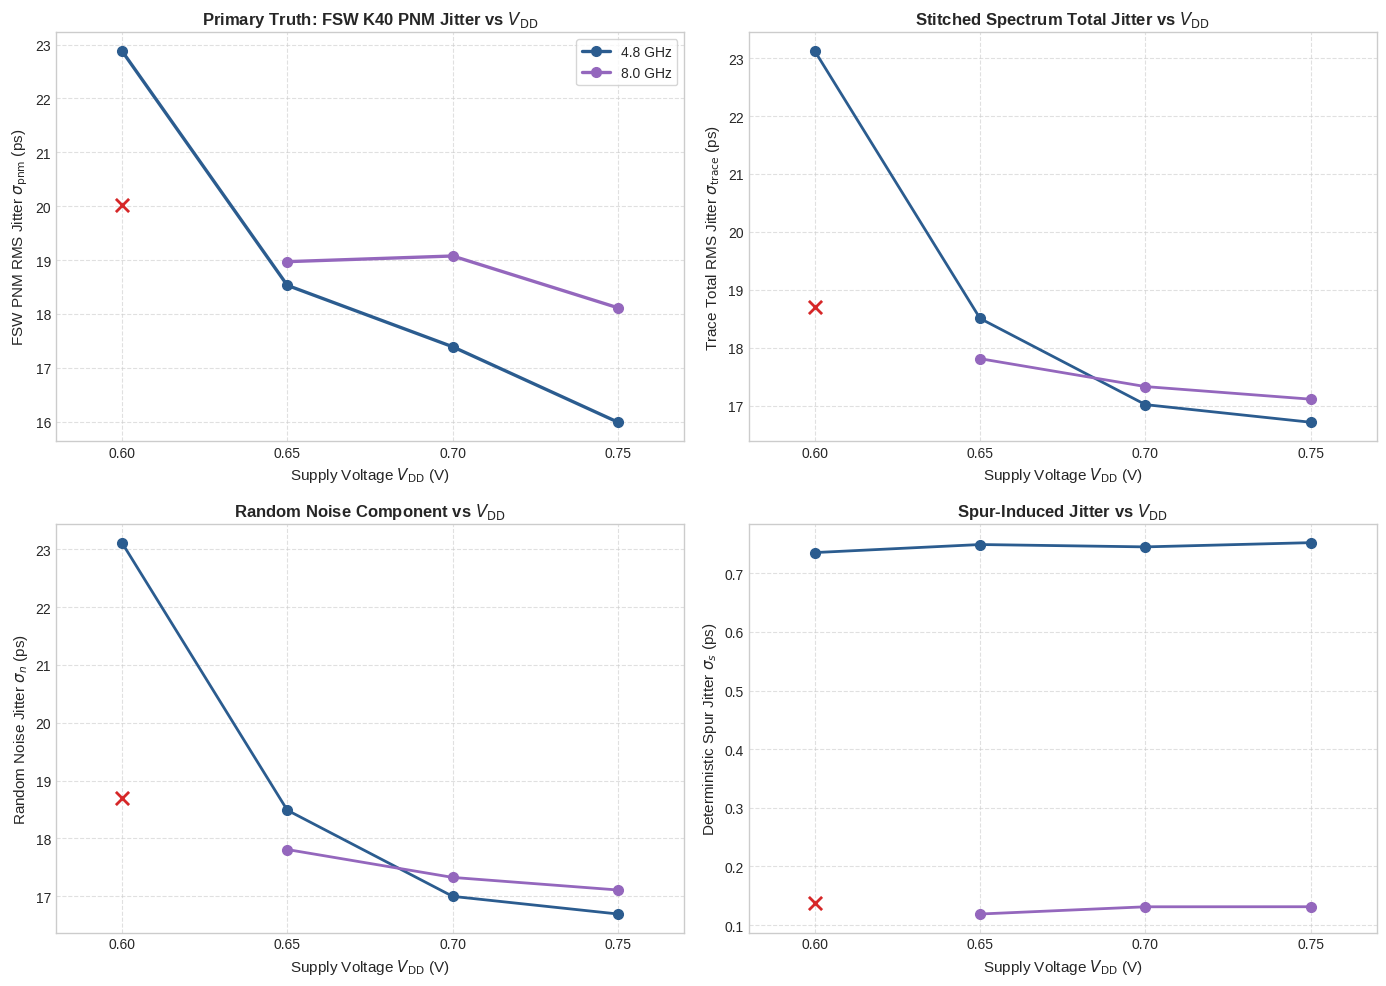

In [64]:
def plot_jitter_vs_vdd_multipanel(df):
    """4-panel visualization of Jitter metrics vs Supply Voltage, with PNM jitter as primary truth."""
    fig, axs = plt.subplots(2, 2, figsize=(14, 10))
    axs = axs.ravel()
    
    # PNM Jitter is the primary source of truth (Panel 1)
    metrics = [
        ("time_jitter_pnm_ps", "FSW PNM RMS Jitter $\\sigma_{\\text{pnm}}$ (ps)", "Primary Truth: FSW K40 PNM Jitter vs $V_{\\text{DD}}$"),
        ("time_jitter_trace_ps", "Trace Total RMS Jitter $\\sigma_{\\text{trace}}$ (ps)", "Stitched Spectrum Total Jitter vs $V_{\\text{DD}}$"),
        ("time_jitter_noise_ps", "Random Noise Jitter $\\sigma_n$ (ps)", "Random Noise Component vs $V_{\\text{DD}}$"),
        ("time_jitter_spur_ps", "Deterministic Spur Jitter $\\sigma_s$ (ps)", "Spur-Induced Jitter vs $V_{\\text{DD}}$"),
    ]
    
    unique_freqs = sorted(df["f_vco"].unique())
    
    for i, (col, ylabel, title) in enumerate(metrics):
        ax = axs[i]
        if col not in df.columns:
            ax.text(0.5, 0.5, f"Column '{col}' not available in dataset", ha="center", va="center")
            continue
            
        for f in unique_freqs:
            sub = df[df["f_vco"] == f].sort_values("vdd_set")
            color = FREQ_COLORS.get(f, "#333333")
            f_lbl = f"{f/1e9:.1f} GHz"
            
            # Plot locked points
            locked_sub = sub[(sub["locked"] == 1) & sub[col].notna()]
            if not locked_sub.empty:
                lw = 2.4 if i == 0 else 2.0
                ax.plot(
                    locked_sub["vdd_set"], locked_sub[col],
                    marker="o", linewidth=lw, label=f_lbl, color=color
                )
                
            # Highlight unlocked / failed points with red 'x'
            unlocked_sub = sub[sub["locked"] == 0]
            if not unlocked_sub.empty:
                y_max = locked_sub[col].max() * 1.05 if not locked_sub.empty else 5.0
                ax.scatter(
                    unlocked_sub["vdd_set"], [y_max] * len(unlocked_sub),
                    marker="x", s=90, color="#d62728", zorder=5
                )
                
        ax.set_xlabel("Supply Voltage $V_{\\text{DD}}$ (V)", fontsize=11)
        ax.set_ylabel(ylabel, fontsize=11)
        ax.set_title(title, fontsize=12, fontweight="bold")
        ax.set_xticks([0.60, 0.65, 0.70, 0.75])
        ax.set_xlim(0.58, 0.77)
        ax.grid(True, linestyle="--", alpha=0.6)
        if i == 0:
            ax.legend(frameon=True, fontsize=10, loc="upper right")
            
    plt.tight_layout()
    plt.show()

plot_jitter_vs_vdd_multipanel(df_runs)


### 4. Supply Current, Core Power & Power Efficiency (mW/GHz)
Evaluates core power dissipation and normalized power efficiency:
$$P_{\text{core}} = V_{\text{DD}} \cdot I_{\text{core}} \quad [\text{mW}]$$
$$\eta_{\text{power}} = \frac{P_{\text{core}}}{f_{\text{VCO}}} \quad \left[\frac{\text{mW}}{\text{GHz}} \equiv \frac{\text{pJ}}{\text{cycle}}\right]$$
Power efficiency normalizes core dissipation by operating frequency, providing a direct metric of energy consumed per clock cycle. The plots below inspect power dissipation, frequency-normalized efficiency scaling across $V_{\text{DD}}$, and the **Power-Jitter Pareto trade-off frontier**.


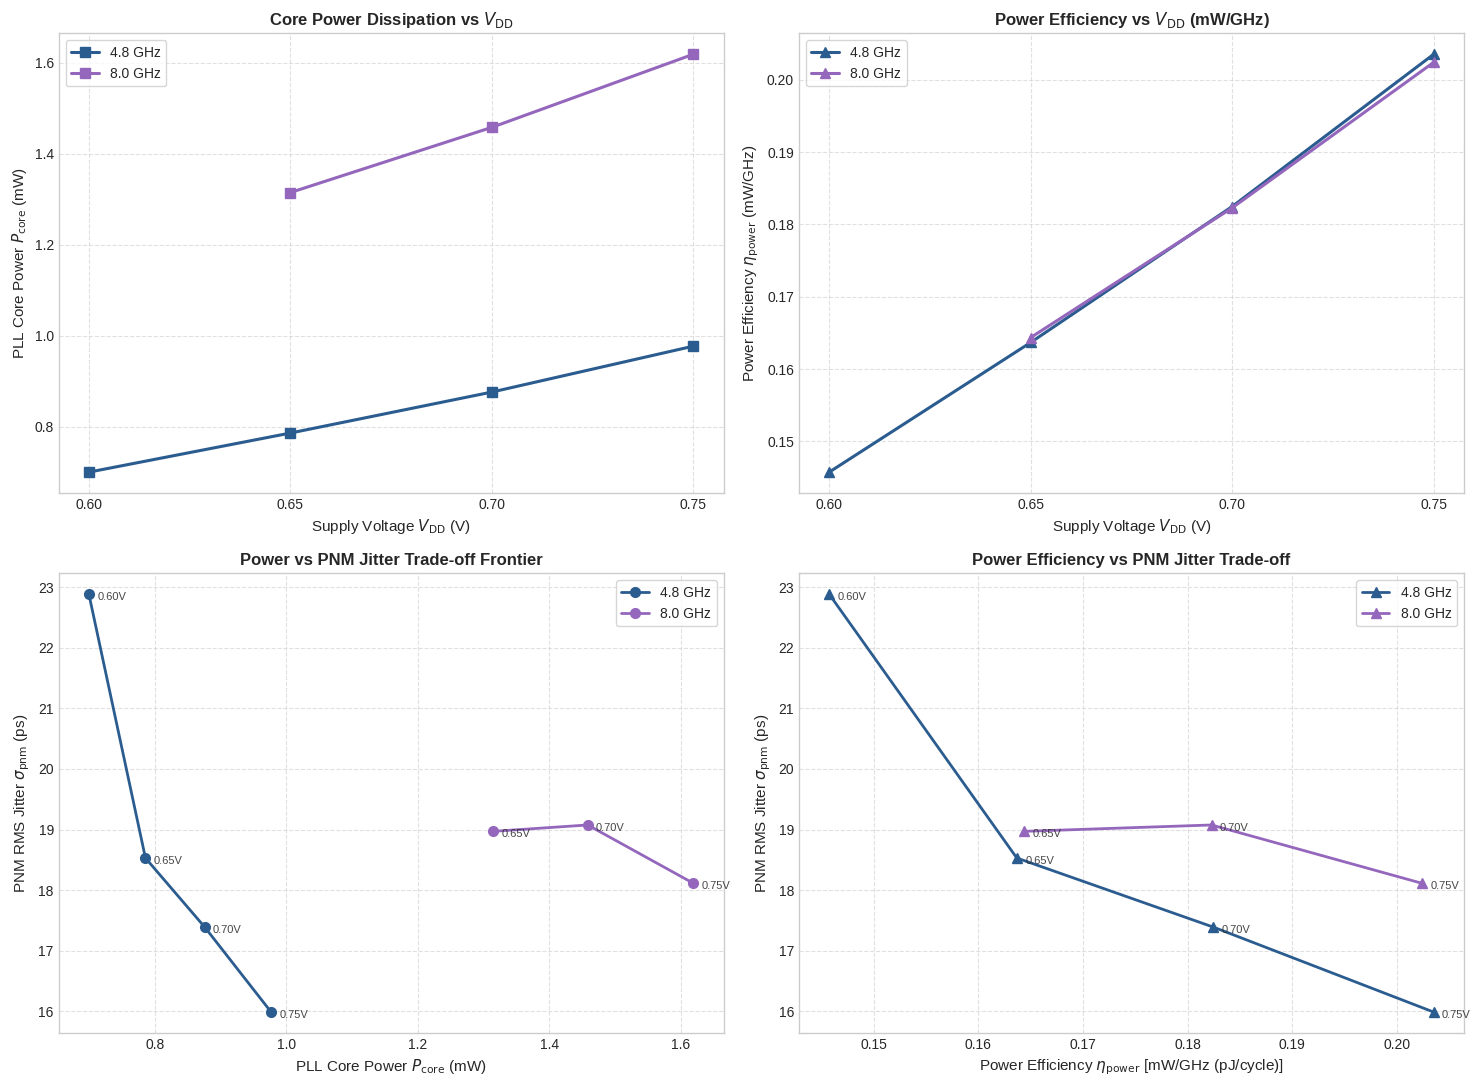

In [65]:
def plot_power_and_tradeoff(df):
    """Plots Power, Power Efficiency (mW/GHz), and Power-Jitter trade-off frontiers using PNM Jitter."""
    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    axs = axs.ravel()
    ax1, ax2, ax3, ax4 = axs
    
    unique_freqs = sorted(df["f_vco"].unique())
    jit_col = "time_jitter_pnm_ps" if ("time_jitter_pnm_ps" in df.columns and df["time_jitter_pnm_ps"].notna().any()) else "time_jitter_trace_ps"
    jit_label = "PNM RMS Jitter $\\sigma_{\\text{pnm}}$ (ps)" if jit_col == "time_jitter_pnm_ps" else "Total RMS Jitter $\\sigma_t$ (ps)"
    
    # 1. Total Core Power vs VDD
    for f in unique_freqs:
        sub = df[(df["f_vco"] == f) & (df["locked"] == 1)].sort_values("vdd_set")
        color = FREQ_COLORS.get(f, "#333333")
        f_lbl = f"{f/1e9:.1f} GHz"
        ax1.plot(sub["vdd_set"], sub["pll_p_mw"], marker="s", linewidth=2.2, label=f_lbl, color=color)
        
    ax1.set_xlabel("Supply Voltage $V_{\\text{DD}}$ (V)", fontsize=11)
    ax1.set_ylabel("PLL Core Power $P_{\\text{core}}$ (mW)", fontsize=11)
    ax1.set_title("Core Power Dissipation vs $V_{\\text{DD}}$", fontsize=12, fontweight="bold")
    ax1.set_xticks([0.60, 0.65, 0.70, 0.75])
    ax1.grid(True, linestyle="--", alpha=0.6)
    ax1.legend(frameon=True, fontsize=10)
    
    # 2. Power Efficiency (mW/GHz) vs VDD
    for f in unique_freqs:
        sub = df[(df["f_vco"] == f) & (df["locked"] == 1)].sort_values("vdd_set")
        color = FREQ_COLORS.get(f, "#333333")
        f_lbl = f"{f/1e9:.1f} GHz"
        p_eff = sub["pll_p_mw"] / (f / 1e9)
        ax2.plot(sub["vdd_set"], p_eff, marker="^", linewidth=2.2, label=f_lbl, color=color)
        
    ax2.set_xlabel("Supply Voltage $V_{\\text{DD}}$ (V)", fontsize=11)
    ax2.set_ylabel("Power Efficiency $\\eta_{\\text{power}}$ (mW/GHz)", fontsize=11)
    ax2.set_title("Power Efficiency vs $V_{\\text{DD}}$ (mW/GHz)", fontsize=12, fontweight="bold")
    ax2.set_xticks([0.60, 0.65, 0.70, 0.75])
    ax2.grid(True, linestyle="--", alpha=0.6)
    ax2.legend(frameon=True, fontsize=10)
    
    # 3. Power vs PNM Jitter Trade-off Frontier (Pareto curve)
    for f in unique_freqs:
        sub = df[
            (df["f_vco"] == f) & (df["locked"] == 1) &
            df[jit_col].notna() & df["pll_p_mw"].notna()
        ].sort_values("pll_p_mw")
        color = FREQ_COLORS.get(f, "#333333")
        f_lbl = f"{f/1e9:.1f} GHz"
        ax3.plot(sub["pll_p_mw"], sub[jit_col], marker="o", linewidth=2.0, label=f_lbl, color=color)
        
        # Annotate VDD setpoints
        for _, r in sub.iterrows():
            ax3.annotate(
                f"{r['vdd_set']:.2f}V",
                (r["pll_p_mw"], r[jit_col]),
                textcoords="offset points", xytext=(6, -4), fontsize=8, alpha=0.85
            )
            
    ax3.set_xlabel("PLL Core Power $P_{\\text{core}}$ (mW)", fontsize=11)
    ax3.set_ylabel(jit_label, fontsize=11)
    ax3.set_title("Power vs PNM Jitter Trade-off Frontier", fontsize=12, fontweight="bold")
    ax3.grid(True, linestyle="--", alpha=0.6)
    ax3.legend(frameon=True, fontsize=10)

    # 4. Power Efficiency vs PNM Jitter Trade-off (Energy per cycle vs Timing jitter)
    for f in unique_freqs:
        sub = df[
            (df["f_vco"] == f) & (df["locked"] == 1) &
            df[jit_col].notna() & df["pll_p_mw"].notna()
        ].sort_values("pll_p_mw")
        color = FREQ_COLORS.get(f, "#333333")
        f_lbl = f"{f/1e9:.1f} GHz"
        p_eff = sub["pll_p_mw"] / (f / 1e9)
        ax4.plot(p_eff, sub[jit_col], marker="^", linewidth=2.0, label=f_lbl, color=color)
        
        # Annotate VDD setpoints
        for _, r in sub.iterrows():
            eff_pt = r["pll_p_mw"] / (f / 1e9)
            ax4.annotate(
                f"{r['vdd_set']:.2f}V",
                (eff_pt, r[jit_col]),
                textcoords="offset points", xytext=(6, -4), fontsize=8, alpha=0.85
            )
            
    ax4.set_xlabel("Power Efficiency $\\eta_{\\text{power}}$ [mW/GHz (pJ/cycle)]", fontsize=11)
    ax4.set_ylabel(jit_label, fontsize=11)
    ax4.set_title("Power Efficiency vs PNM Jitter Trade-off", fontsize=12, fontweight="bold")
    ax4.grid(True, linestyle="--", alpha=0.6)
    ax4.legend(frameon=True, fontsize=10)
    
    plt.tight_layout()
    plt.show()

plot_power_and_tradeoff(df_runs)


### 5. Phase Noise Spectra ($L(f)$) Evolution Across $V_{\text{DD}}$
Phase noise curves referred to the VCO output:
$$\mathcal{L}_{\text{VCO}}(f) = \mathcal{L}_{\text{pad}}(f) + 20\log_{10}(N)$$
where $N = \text{total\_div} = 64$.
- **In-band ($f < 1\,\text{MHz}$)**: Charge pump current and phase detector headroom degrade at lower $V_{\text{DD}}$, contracting loop bandwidth.
- **Out-of-band ($f > 3\,\text{MHz}$)**: VCO tank oscillation amplitude drops with supply ($V_{\text{tank}} \propto V_{\text{DD}}$), raising the thermal noise floor.


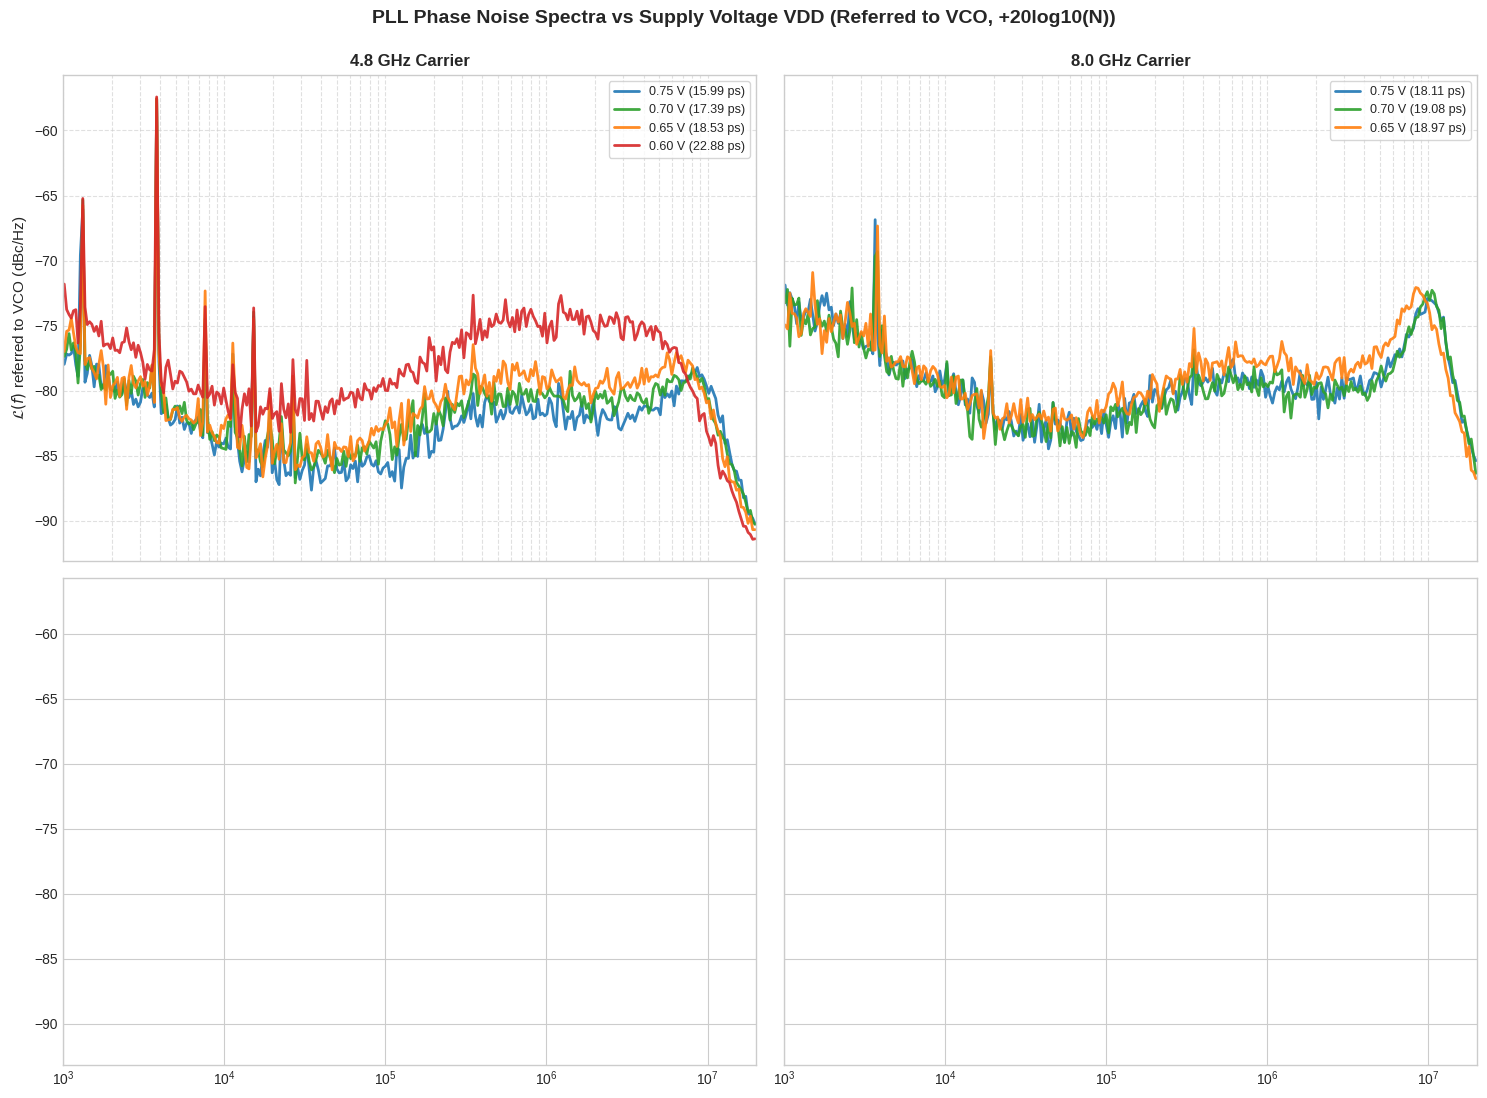

In [66]:
def plot_phase_noise_vdd_evolution(df_runs, df_traces, ref_to_vco=True):
    """2x2 grid showing Phase Noise evolution across VDD for each carrier frequency."""
    if df_traces is None or df_traces.empty or "kind" not in df_traces.columns:
        print("No phase noise traces available in dataset.")
        return
        
    target_kind = "L_trace" if "L_trace" in df_traces["kind"].values else "L_pnmode"
    sub_traces = df_traces[df_traces["kind"] == target_kind].copy()
    if sub_traces.empty:
        print("No L_trace or L_pnmode traces found.")
        return
        
    unique_freqs = sorted(df_runs["f_vco"].unique())
    fig, axs = plt.subplots(2, 2, figsize=(15, 11), sharex=True, sharey=True)
    axs = axs.ravel()
    
    for i, f in enumerate(unique_freqs[:4]):
        ax = axs[i]
        f_ghz = f / 1e9
        div_db = 20 * math.log10(64) if ref_to_vco else 0.0
        
        runs_f = df_runs[df_runs["f_vco"] == f].sort_values("vdd_set", ascending=False)
        
        for _, r in runs_f.iterrows():
            if r["locked"] != 1:
                continue
            v = r["vdd_set"]
            
            # Match traces by frequency and supply
            t_match = sub_traces[
                (sub_traces["f_vco"] == f) & 
                (np.isclose(sub_traces["vdd_set"], v, atol=0.03))
            ]
            if t_match.empty:
                continue
                
            # Bin for smooth visual display
            t_match = t_match.sort_values("freq")
            f_bin, l_bin = bin_phase_noise(t_match["freq"], t_match["level_dbm"])
            
            color = VDD_COLORS.get(v, "#333333")
            j_val = r['time_jitter_pnm_ps'] if ('time_jitter_pnm_ps' in r and pd.notna(r['time_jitter_pnm_ps'])) else r.get('time_jitter_trace_ps', np.nan)
            jitter_str = f"{j_val:.2f} ps" if not pd.isna(j_val) else ""
            lbl = f"{v:.2f} V ({jitter_str})"
            
            ax.plot(f_bin, l_bin + div_db, label=lbl, color=color, linewidth=2.0, alpha=0.9)
            
        ax.set_xscale("log")
        ax.set_xlim(1e3, 20e6)
        ax.set_title(f"{f_ghz:.1f} GHz Carrier", fontsize=12, fontweight="bold")
        ax.grid(True, which="both", linestyle="--", alpha=0.6)
        ax.legend(frameon=True, fontsize=9, loc="upper right")
        if i in (2, 3):
            ax.set_xlabel("Offset Frequency (Hz)", fontsize=11)
        if i in (0, 2):
            ylabel = r"$\mathcal{L}(f)$ referred to VCO (dBc/Hz)" if ref_to_vco else r"$\mathcal{L}(f)$ at Pad (dBc/Hz)"
            ax.set_ylabel(ylabel, fontsize=11)
            
    ref_str = " (Referred to VCO, +20log10(N))" if ref_to_vco else " (Measured at Pad)"
    fig.suptitle(f"PLL Phase Noise Spectra vs Supply Voltage VDD{ref_str}", fontsize=14, fontweight="bold", y=0.995)
    plt.tight_layout()
    plt.show()

plot_phase_noise_vdd_evolution(df_runs, df_traces, ref_to_vco=True)


### 6. Reference Spur & Harmonic Behavior vs $V_{\text{DD}}$
Examines reference spur suppression:
$$P_{\text{spur,dBc}} = P_{\text{spur,dBm}} - P_{\text{carrier,dBm}}$$
at offset $f_{\text{ref}} = f_{\text{VCO}} / 64$ across supply scaling.


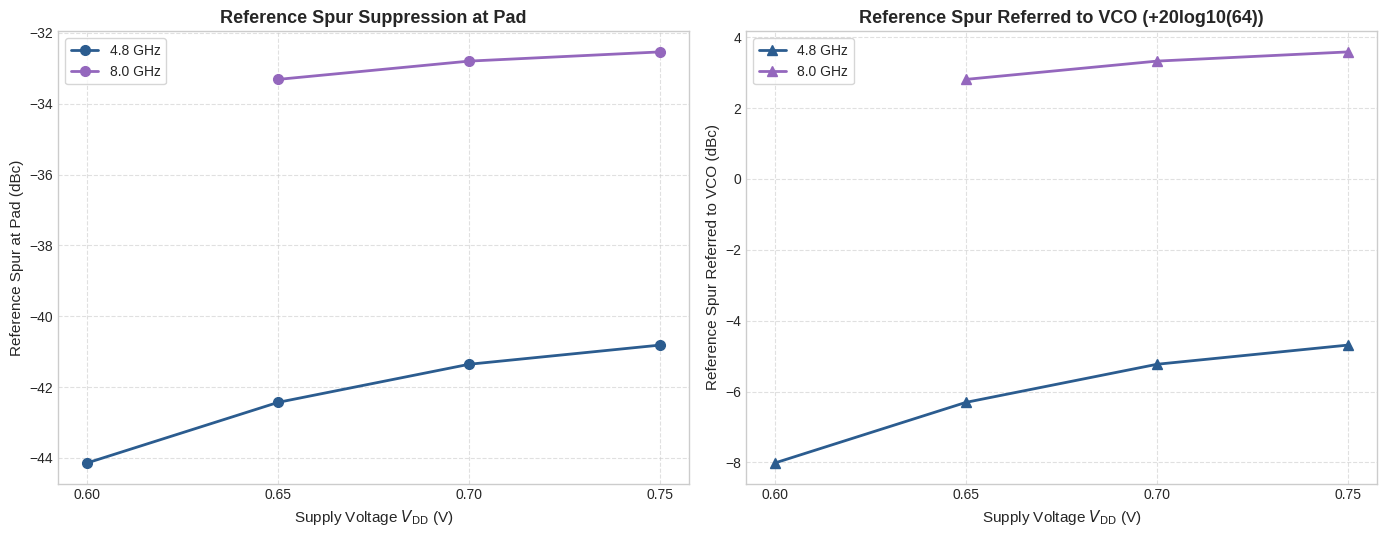

In [67]:
def plot_reference_spur_vs_vdd(df):
    """Plots Reference Spur suppression (dBc) vs Supply Voltage."""
    if "ref_spur_dbc" not in df.columns or df["ref_spur_dbc"].dropna().empty:
        print("Reference spur data not available in dataset.")
        return
        
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
    unique_freqs = sorted(df["f_vco"].unique())
    
    # 1. Spur Suppression at Pad (dBc)
    for f in unique_freqs:
        sub = df[(df["f_vco"] == f) & (df["locked"] == 1)].sort_values("vdd_set")
        color = FREQ_COLORS.get(f, "#333333")
        f_lbl = f"{f/1e9:.1f} GHz"
        ax1.plot(sub["vdd_set"], sub["ref_spur_dbc"], marker="o", linewidth=2.0, label=f_lbl, color=color)
        
    ax1.set_xlabel("Supply Voltage $V_{\\text{DD}}$ (V)", fontsize=11)
    ax1.set_ylabel("Reference Spur at Pad (dBc)", fontsize=11)
    ax1.set_title("Reference Spur Suppression at Pad", fontsize=13, fontweight="bold")
    ax1.set_xticks([0.60, 0.65, 0.70, 0.75])
    ax1.grid(True, linestyle="--", alpha=0.6)
    ax1.legend(frameon=True, fontsize=10)
    
    # 2. Spur Referred to VCO (dBc)
    div_db = 20 * math.log10(64)
    for f in unique_freqs:
        sub = df[(df["f_vco"] == f) & (df["locked"] == 1)].sort_values("vdd_set")
        color = FREQ_COLORS.get(f, "#333333")
        f_lbl = f"{f/1e9:.1f} GHz"
        spur_vco = sub["ref_spur_vco_dbc"] if "ref_spur_vco_dbc" in sub.columns else (sub["ref_spur_dbc"] + div_db)
        ax2.plot(sub["vdd_set"], spur_vco, marker="^", linewidth=2.0, label=f_lbl, color=color)
        
    ax2.set_xlabel("Supply Voltage $V_{\\text{DD}}$ (V)", fontsize=11)
    ax2.set_ylabel("Reference Spur Referred to VCO (dBc)", fontsize=11)
    ax2.set_title("Reference Spur Referred to VCO (+20log10(64))", fontsize=13, fontweight="bold")
    ax2.set_xticks([0.60, 0.65, 0.70, 0.75])
    ax2.grid(True, linestyle="--", alpha=0.6)
    ax2.legend(frameon=True, fontsize=10)
    
    plt.tight_layout()
    plt.show()

plot_reference_spur_vs_vdd(df_runs)


### 7. Interactive Multi-Metric Explorer (Plotly)
Interactive visualization inspired by [`sw/tools/notebooks/pll_test_vdd.ipynb`](file:///users/micas/iramrezl/projects/lagd-meas/sw/tools/notebooks/pll_test_vdd.ipynb), supporting hover inspection of exact jitter, power, and supply voltages with HTML/PNG export.


In [68]:
def plot_interactive_vdd_explorer(df, fig_dir=FIG_DIR):
    """Interactive Plotly figures comparing Jitter and Power Efficiency vs VDD."""
    # 1. Jitter vs VDD
    fig_j = go.Figure()
    for f, grp in df.groupby("f_ghz"):
        grp_locked = grp[grp["locked"] == 1].sort_values("vdd_set")
        f_color = FREQ_COLORS.get(f * 1e9, "#1f77b4")
        fig_j.add_trace(go.Scatter(
            x=grp_locked["vdd_set"],
            y=grp_locked["time_jitter_pnm_ps"] if ("time_jitter_pnm_ps" in grp_locked.columns and grp_locked["time_jitter_pnm_ps"].notna().any()) else grp_locked["time_jitter_trace_ps"],
            mode="lines+markers",
            name=f"{f:.1f} GHz Jitter",
            line=dict(color=f_color, width=2.5),
            marker=dict(size=8),
            hovertemplate="<b>%{x:.2f} V</b><br>PNM Jitter: %{y:.2f} ps<extra>" + f"{f:.1f} GHz" + "</extra>"
        ))
        
    fig_j.update_layout(
        title="Interactive PNM Jitter vs Supply Voltage (VDD)",
        xaxis=dict(title="PLL Supply VDD [V]", tickvals=[0.60, 0.65, 0.70, 0.75], gridcolor=GRID_COLOR),
        yaxis=dict(title="FSW K40 PNM RMS Jitter [ps]", rangemode="tozero", gridcolor=GRID_COLOR),
        template="plotly_white",
        height=480,
        legend=dict(orientation="h", y=-0.2)
    )
    save_fig(fig_j, "interactive_jitter_vs_vdd", fig_dir=fig_dir)

    # 2. Power Efficiency (mW/GHz) vs VDD
    fig_e = go.Figure()
    for f, grp in df.groupby("f_ghz"):
        grp_locked = grp[grp["locked"] == 1].sort_values("vdd_set")
        f_color = FREQ_COLORS.get(f * 1e9, "#1f77b4")
        f_num = float(f)
        eff = grp_locked["p_eff_mw_per_ghz"] if "p_eff_mw_per_ghz" in grp_locked.columns else grp_locked["pll_p_mw"] / f_num
        pwr = grp_locked["pll_p_mw"].round(2).astype(str)
        fig_e.add_trace(go.Scatter(
            x=grp_locked["vdd_set"],
            y=eff,
            mode="lines+markers",
            name=f"{f:.1f} GHz Efficiency",
            line=dict(color=f_color, width=2.5),
            marker=dict(size=8, symbol="triangle-up"),
            hovertemplate="<b>%{x:.2f} V</b><br>Efficiency: %{y:.3f} mW/GHz<extra>" + f"{f:.1f} GHz" + "</extra>"
        ))
        
    fig_e.update_layout(
        title="Interactive Power Efficiency vs Supply Voltage (VDD)",
        xaxis=dict(title="PLL Supply VDD [V]", tickvals=[0.60, 0.65, 0.70, 0.75], gridcolor=GRID_COLOR),
        yaxis=dict(title="Power Efficiency [mW/GHz (pJ/cycle)]", rangemode="tozero", gridcolor=GRID_COLOR),
        template="plotly_white",
        height=480,
        legend=dict(orientation="h", y=-0.2)
    )
    save_fig(fig_e, "interactive_power_efficiency_vs_vdd", fig_dir=fig_dir)

plot_interactive_vdd_explorer(df_runs)


### 8. Single Frequency Deep-Dive
Select any individual carrier frequency to inspect its dedicated performance profile, supply sensitivity curve, and detailed metrics.


=== DETAILED DIAGNOSTIC REPORT: 4.8 GHz (I=7, R1=7, C1=7, C2=0) ===


,Freq (GHz),VDD Target (V),VDD Meas (V),Lock Status,PNM Jitter (ps),Trace Jitter (ps),Noise Jitter (ps),Spur Jitter (ps),Ref Spur (dBc),Power (mW),Current (mA),Power Eff (mW/GHz)
0,4.8,0.75,0.750,LOCKED,15.99,16.71,16.69,0.75,-40.8,0.98,1.30,0.204
1,4.8,0.70,0.700,LOCKED,17.39,17.02,17.00,0.75,-41.4,0.88,1.25,0.182
2,4.8,0.65,0.652,LOCKED,18.53,18.50,18.49,0.75,-42.4,0.79,1.21,0.164
3,4.8,0.60,0.602,LOCKED,22.88,23.13,23.11,0.74,-44.1,0.70,1.16,0.146


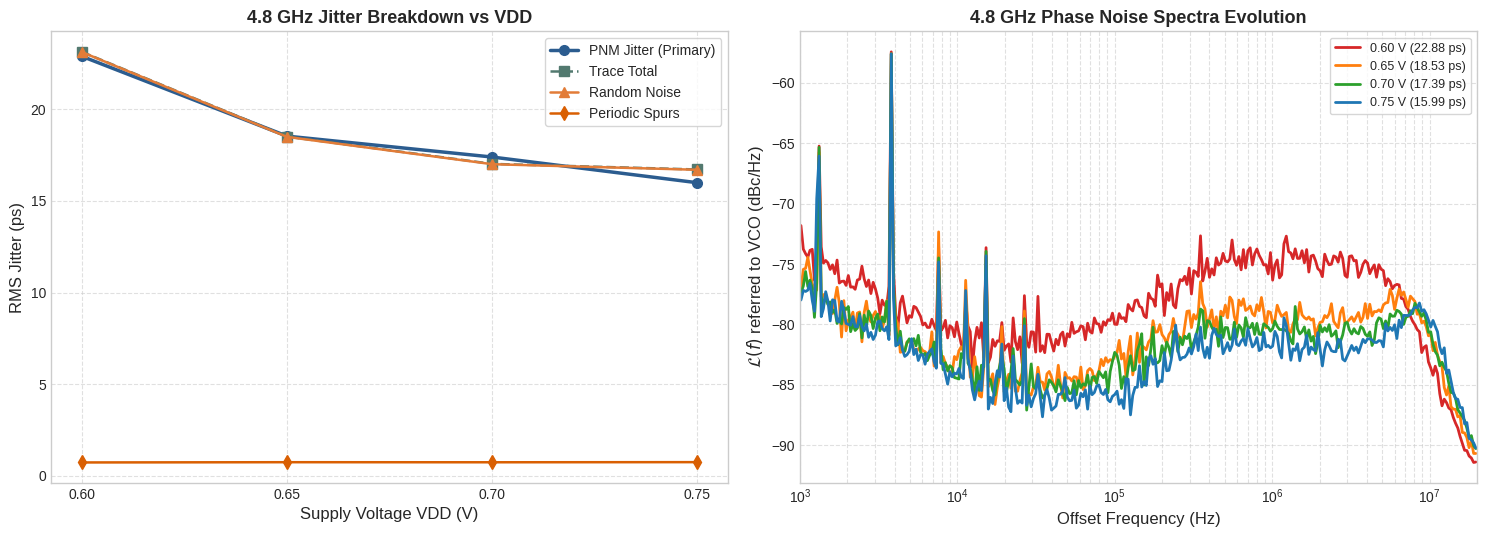

In [69]:
# ==============================================================================
# FREQUENCY DEEP-DIVE SELECTOR
# Choose one of: 4.8e9, 6.0e9, 7.0e9, 8.0e9
# ==============================================================================
AVAILABLE_FREQS = sorted(df_runs["f_vco"].unique())
SELECTED_FREQ = 6.0e9 if 6.0e9 in AVAILABLE_FREQS else (AVAILABLE_FREQS[0] if AVAILABLE_FREQS else 4.8e9)

def display_single_frequency_deep_dive(df_runs, df_traces, target_freq=SELECTED_FREQ):
    """Detailed diagnostic report and plots for a single operating frequency."""
    sub = df_runs[df_runs["f_vco"] == target_freq].sort_values("vdd_set", ascending=False)
    if sub.empty:
        print(f"No data found for target frequency {target_freq/1e9:.1f} GHz.")
        return
        
    f_ghz = target_freq / 1e9
    cfg_lbl = sub.iloc[0].get("config_label", f"I={int(sub.iloc[0]['set_current'])}, R1={int(sub.iloc[0]['set_r1'])}, C1={int(sub.iloc[0]['set_c1'])}, C2={int(sub.iloc[0]['set_c2'])}" if "set_current" in sub.columns and pd.notna(sub.iloc[0]["set_current"]) else f"{f_ghz:.1f} GHz")
    print(f"=== DETAILED DIAGNOSTIC REPORT: {f_ghz:.1f} GHz ({cfg_lbl}) ===")
    display(format_vdd_summary_table(sub))
    
    # 2-panel figure for this frequency: (a) Jitter breakdown, (b) Phase Noise overlay
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
    
    locked_sub = sub[sub["locked"] == 1].sort_values("vdd_set")
    
    # Panel 1: Jitter breakdown (PNM jitter as primary truth)
    if "time_jitter_pnm_ps" in locked_sub.columns and locked_sub["time_jitter_pnm_ps"].notna().any():
        ax1.plot(locked_sub["vdd_set"], locked_sub["time_jitter_pnm_ps"], marker="o", linewidth=2.5, label="PNM Jitter (Primary)", color="#2b5c8f")
    ax1.plot(locked_sub["vdd_set"], locked_sub["time_jitter_trace_ps"], marker="s", linewidth=1.8, linestyle="--", label="Trace Total", color="#52796f")
    if "time_jitter_noise_ps" in locked_sub.columns and locked_sub["time_jitter_noise_ps"].notna().any():
        ax1.plot(locked_sub["vdd_set"], locked_sub["time_jitter_noise_ps"], marker="^", linewidth=1.8, label="Random Noise", color="#e27c38")
    if "time_jitter_spur_ps" in locked_sub.columns and locked_sub["time_jitter_spur_ps"].notna().any():
        ax1.plot(locked_sub["vdd_set"], locked_sub["time_jitter_spur_ps"], marker="d", linewidth=1.8, label="Periodic Spurs", color="#d95f02")
    ax1.set_xlabel("Supply Voltage VDD (V)")
    ax1.set_ylabel("RMS Jitter (ps)")
    ax1.set_title(f"{f_ghz:.1f} GHz Jitter Breakdown vs VDD", fontweight="bold")
    ax1.set_xticks([0.60, 0.65, 0.70, 0.75])
    ax1.grid(True, linestyle="--", alpha=0.6)
    ax1.legend(frameon=True)
    
    # Panel 2: Phase noise overlay
    if not df_traces.empty and "kind" in df_traces.columns:
        target_kind = "L_trace" if "L_trace" in df_traces["kind"].values else "L_pnmode"
        sub_t = df_traces[(df_traces["kind"] == target_kind) & (df_traces["f_vco"] == target_freq)]
        div_db = 20 * math.log10(64)
        for _, r in locked_sub.iterrows():
            v = r["vdd_set"]
            t_m = sub_t[np.isclose(sub_t["vdd_set"], v, atol=0.03)].sort_values("freq")
            if not t_m.empty:
                fb, lb = bin_phase_noise(t_m["freq"], t_m["level_dbm"])
                color = VDD_COLORS.get(v, "#333333")
                j_val = r['time_jitter_pnm_ps'] if ('time_jitter_pnm_ps' in r and pd.notna(r['time_jitter_pnm_ps'])) else r.get('time_jitter_trace_ps', np.nan)
                lbl = f"{v:.2f} V ({j_val:.2f} ps)" if not pd.isna(j_val) else f"{v:.2f} V"
                ax2.plot(fb, lb + div_db, label=lbl, color=color, linewidth=2.0)
                
        ax2.set_xscale("log")
        ax2.set_xlim(1e3, 20e6)
        ax2.set_xlabel("Offset Frequency (Hz)")
        ax2.set_ylabel(r"$\mathcal{L}(f)$ referred to VCO (dBc/Hz)")
        ax2.set_title(f"{f_ghz:.1f} GHz Phase Noise Spectra Evolution", fontweight="bold")
        ax2.grid(True, which="both", linestyle="--", alpha=0.6)
        ax2.legend(frameon=True, fontsize=9)
        
    plt.tight_layout()
    plt.show()

display_single_frequency_deep_dive(df_runs, df_traces, SELECTED_FREQ)


### 9. Executive Summary & Operating Recommendations
Summary of safe supply operating ranges, minimum operating voltages, and recommended setpoints for low-power operation.


In [70]:
print("=" * 85)
print("  EXECUTIVE SUMMARY: PLL VDD SENSITIVITY & OPERATING MARGINS")
print("=" * 85)

for f, grp in df_runs.groupby("f_ghz"):
    locked_pts = grp[grp["locked"] == 1].sort_values("vdd_set")
    nom = grp[grp["vdd_set"] == 0.75]
    
    if locked_pts.empty:
        print(f"\n• {f:.1f} GHz Configuration: UNLOCKED across all measured supplies!")
        continue
        
    min_v = locked_pts["vdd_set"].min()
    nom_j = nom.iloc[0]["time_jitter_pnm_ps"] if (not nom.empty and "time_jitter_pnm_ps" in nom.columns and pd.notna(nom.iloc[0]["time_jitter_pnm_ps"])) else (nom.iloc[0].get("time_jitter_trace_ps", np.nan) if not nom.empty else np.nan)
    nom_p = nom.iloc[0]["pll_p_mw"] if not nom.empty else np.nan
    
    low_row = locked_pts[locked_pts["vdd_set"] == min_v].iloc[0]
    low_j = low_row["time_jitter_pnm_ps"] if ("time_jitter_pnm_ps" in low_row and pd.notna(low_row["time_jitter_pnm_ps"])) else low_row.get("time_jitter_trace_ps", np.nan)
    low_p = low_row["pll_p_mw"]
    
    dj = low_j - nom_j
    dp_pct = (1.0 - low_p / nom_p) * 100.0 if nom_p > 0 else 0.0
    
    if min_v <= 0.65:
        rec = f"Safe to scale to 0.70 V (saving ~{(1 - low_p*1.1/nom_p)*100:.0f}% power with negligible jitter penalty)."
    else:
        rec = "Keep at nominal 0.75 V to avoid operating near the unlock boundary."
        
    cfg_lbl = low_row.get("config_label", f"I={int(low_row['set_current'])}, R1={int(low_row['set_r1'])}, C1={int(low_row['set_c1'])}, C2={int(low_row['set_c2'])}" if "set_current" in low_row and pd.notna(low_row["set_current"]) else f"{f:.1f} GHz Opt")
    print(f"\n• {f:.1f} GHz Carrier ({cfg_lbl}):")
    f_num = float(f)
    nom_eff = (nom_p / f_num) if (not np.isnan(nom_p) and f_num > 0) else np.nan
    low_eff = (low_p / f_num) if (not np.isnan(low_p) and f_num > 0) else np.nan
    eff_str = f" (Eff = {nom_eff:.3f} mW/GHz)" if not np.isnan(nom_eff) else ""
    print(f"    - Nominal Performance (0.75 V):  PNM Jitter = {nom_j:.2f} ps, Power = {nom_p:.2f} mW{eff_str}")
    print(f"    - Minimum Operating Supply:       VDD,min = {min_v:.2f} V")
    low_eff_str = f", Eff = {low_eff:.3f} mW/GHz" if not np.isnan(low_eff) else ""
    print(f"    - Performance at VDD,min:        PNM Jitter = {low_j:.2f} ps (+{dj:.2f} ps), Power = {low_p:.2f} mW (-{dp_pct:.1f}%{low_eff_str})")
    print(f"    - Recommendation:                {rec}")

print("\n" + "=" * 85)


  EXECUTIVE SUMMARY: PLL VDD SENSITIVITY & OPERATING MARGINS

• 4.8 GHz Carrier (I=7, R1=7, C1=7, C2=0):
    - Nominal Performance (0.75 V):  PNM Jitter = 15.99 ps, Power = 0.98 mW (Eff = 0.204 mW/GHz)
    - Minimum Operating Supply:       VDD,min = 0.60 V
    - Performance at VDD,min:        PNM Jitter = 22.88 ps (+6.89 ps), Power = 0.70 mW (-28.4%, Eff = 0.146 mW/GHz)
    - Recommendation:                Safe to scale to 0.70 V (saving ~21% power with negligible jitter penalty).

• 8.0 GHz Carrier (I=7, R1=7, C1=7, C2=0):
    - Nominal Performance (0.75 V):  PNM Jitter = 18.11 ps, Power = 1.62 mW (Eff = 0.202 mW/GHz)
    - Minimum Operating Supply:       VDD,min = 0.65 V
    - Performance at VDD,min:        PNM Jitter = 18.97 ps (+0.86 ps), Power = 1.31 mW (-18.8%, Eff = 0.164 mW/GHz)
    - Recommendation:                Safe to scale to 0.70 V (saving ~11% power with negligible jitter penalty).

